--- Part 1: Hyperparameter Tuning with Grid Search ---
Dataset Features: (150, 4)
Dataset Labels: (150,)
Feature Names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target Names: ['setosa' 'versicolor' 'virginica']

Features standardized.

Hyperparameter grid: {'C': [0.1, 1, 10, 100], 'gamma': [1, 0.1, 0.01, 0.001], 'kernel': ['rbf', 'linear']}

Starting Grid Search with 5-fold Cross-Validation...
Fitting 5 folds for each of 32 candidates, totalling 160 fits

Grid Search completed.
Best hyperparameters: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Best CV accuracy: 0.981
Test accuracy: 0.9111

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg     

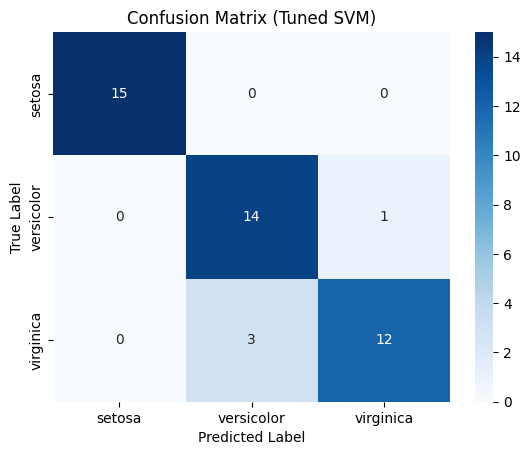


Top 5 Grid Search Results:
    param_C  param_gamma param_kernel  mean_test_score  rank_test_score
10      1.0        0.100          rbf         0.980952                1
27    100.0        0.100       linear         0.980952                1
31    100.0        0.001       linear         0.980952                1
29    100.0        0.010       linear         0.980952                1
25    100.0        1.000       linear         0.980952                1

--- Part 2: K-Fold Cross-Validation ---

Performing 5-fold cross-validation...
Cross-validation scores: [1.         0.95238095 0.95238095 0.95238095 1.        ]
Mean accuracy: 0.9714
Standard deviation: 0.0233


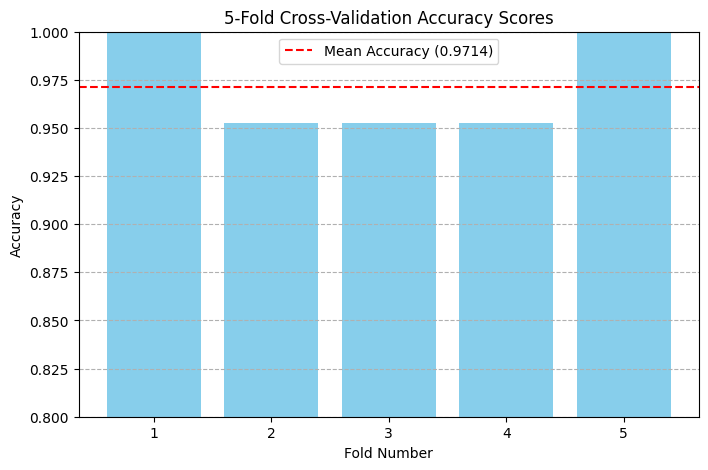


Experiment 8 completed successfully.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Part 1: Hyperparameter Tuning with Grid Search
print("--- Part 1: Hyperparameter Tuning with Grid Search ---")

iris = load_iris()
X, y = iris.data, iris.target
target_names = iris.target_names

print("Dataset Features:", X.shape)
print("Dataset Labels:", y.shape)
print("Feature Names:", iris.feature_names)
print("Target Names:", target_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeatures standardized.")

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'linear']
}

print("\nHyperparameter grid:", param_grid)

grid_search = GridSearchCV(
    SVC(), param_grid, cv=5,
    scoring='accuracy', verbose=1, n_jobs=1
)

print("\nStarting Grid Search with 5-fold Cross-Validation...")
grid_search.fit(X_train_scaled, y_train)

print("\nGrid Search completed.")
print("Best hyperparameters:", grid_search.best_params_)
print("Best CV accuracy:", round(grid_search.best_score_, 4))

best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_scaled)

print("Test accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_tuned, target_names=target_names
))

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(
    cm_tuned, annot=True, fmt='d', cmap='Blues',
    xticklabels=target_names, yticklabels=target_names
)
plt.title("Confusion Matrix (Tuned SVM)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Top 5 Grid Search Results
results_df = pd.DataFrame(grid_search.cv_results_)
print("\nTop 5 Grid Search Results:")
print(
    results_df[
        ['param_C', 'param_gamma', 'param_kernel',
         'mean_test_score', 'rank_test_score']
    ].sort_values('rank_test_score').head()
)

# Part 2: K-Fold Cross-Validation
print("\n--- Part 2: K-Fold Cross-Validation ---")

model_cv = SVC(random_state=42)
k_folds = 5

kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)

print("\nPerforming 5-fold cross-validation...")

cv_scores = cross_val_score(
    model_cv, X_train_scaled, y_train,
    cv=kf, scoring='accuracy'
)

print("Cross-validation scores:", cv_scores)
print("Mean accuracy:", round(np.mean(cv_scores), 4))
print("Standard deviation:", round(np.std(cv_scores), 4))

plt.figure(figsize=(8, 5))
plt.bar(range(1, k_folds + 1), cv_scores, color='skyblue')
plt.axhline(
    y=np.mean(cv_scores), color='red', linestyle='--',
    label=f'Mean Accuracy ({np.mean(cv_scores):.4f})'
)
plt.title("5-Fold Cross-Validation Accuracy Scores")
plt.xlabel("Fold Number")
plt.ylabel("Accuracy")
plt.ylim(0.8, 1.0)
plt.legend()
plt.grid(axis='y', linestyle='--')
plt.show()

print("\nExperiment 8 completed successfully.")
